In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage


In [2]:
# 1. Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
# 2. Select numerical features
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

In [4]:
# 3. Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

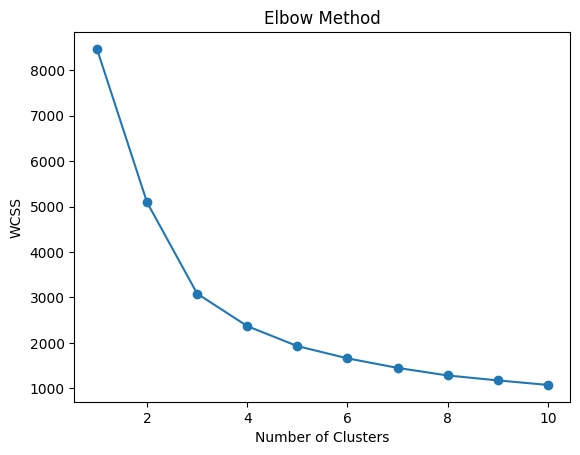

In [5]:
# 4. Elbow method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [6]:
# 5. K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts())


K-Means Cluster Counts:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


In [7]:
# 6. Hierarchical clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts())


Hierarchical Cluster Counts:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64


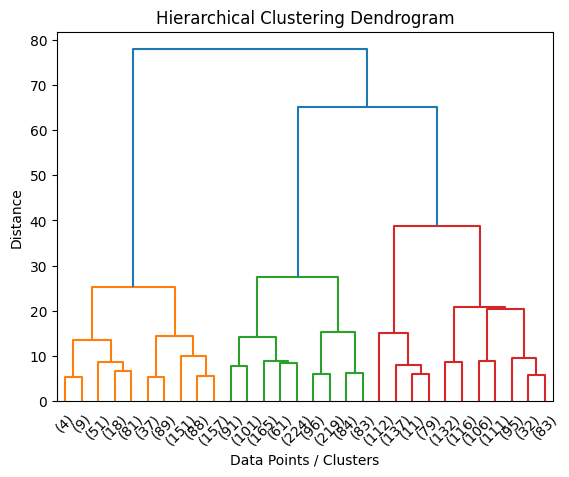

In [8]:
# 7. Dendrogram
linked = linkage(X_scaled, method="ward")
dendrogram(linked, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Clusters")
plt.ylabel("Distance")
plt.show()
